In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns

from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.utils import df_features_to_numpy, df_target_to_numpy
from src.graficos import plot_confusion_matrix

# Cargo el dataset ya procesado

In [12]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [13]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [14]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    54017
HARDCOVER    22385
EBOOK        17247
UNKNOWN       4160
AUDIO         1597
OTHER          551
COMIC           43
Name: count, dtype: int64


In [15]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [16]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import one_hot_format, multi_binarizer_genre
df = one_hot_format(df) #one hot de format
df = multi_binarizer_genre(df) #multi binarizer de genero

In [17]:
#TEMPORAL: normalmente va a haber que cargar los 3 datasets, ya splitteados
df_dev, df_test = train_test_split(df, test_size = 0.2, stratify = df["estrellas"], random_state = 42)
df_train, df_val = train_test_split(df_dev, test_size = 0.2, stratify = df_dev["estrellas"], random_state = 42)

## Preparacion de los datos

In [18]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK', 'format_group_UNKNOWN'] + generos

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## Regresion Lineal con features basicas

In [19]:
modeloBaseRegresionLineal = LinearRegression() 
modeloBaseRegresionLineal.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLineal = modeloBaseRegresionLineal.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloBaseRegresionLineal, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloBaseRegresionLineal, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.238534    0.238989
RMSE  0.488400    0.488865
MAE   0.335976    0.336009
R²    0.053280    0.051929


## Regresion Logistica con features basicas

c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              Train  Validation
Accuracy   0.776500    0.776563
Precision  0.346117    0.310011
Recall     0.167234    0.167152
F1         0.146906    0.146776


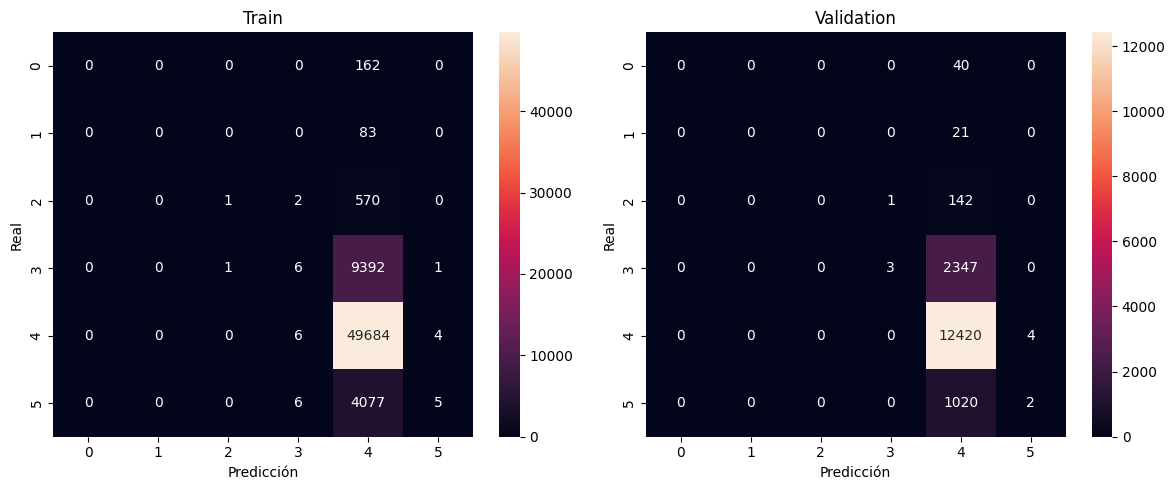

In [28]:
modeloBaseRegresionLogistica = LogisticRegression(max_iter = 1000)
modeloBaseRegresionLogistica.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_train_scaled)
y_pred_val_modeloBaseRegresionLogistica = modeloBaseRegresionLogistica.predict(X_val_scaled)

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloBaseRegresionLogistica, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloBaseRegresionLogistica, y_val_clasificacion)
tabla_metricas_regresion_logistica_base = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_base)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloBaseRegresionLogistica)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloBaseRegresionLogistica)
plot_confusion_matrix(cm_train, cm_val)

### Balanceo de clases

El primer balanceo que intento es el predeterminado de scikit learn

              Train  Validation
Accuracy   0.494266    0.497750
Precision  0.224562    0.224676
Recall     0.392635    0.376401
F1         0.211261    0.211253


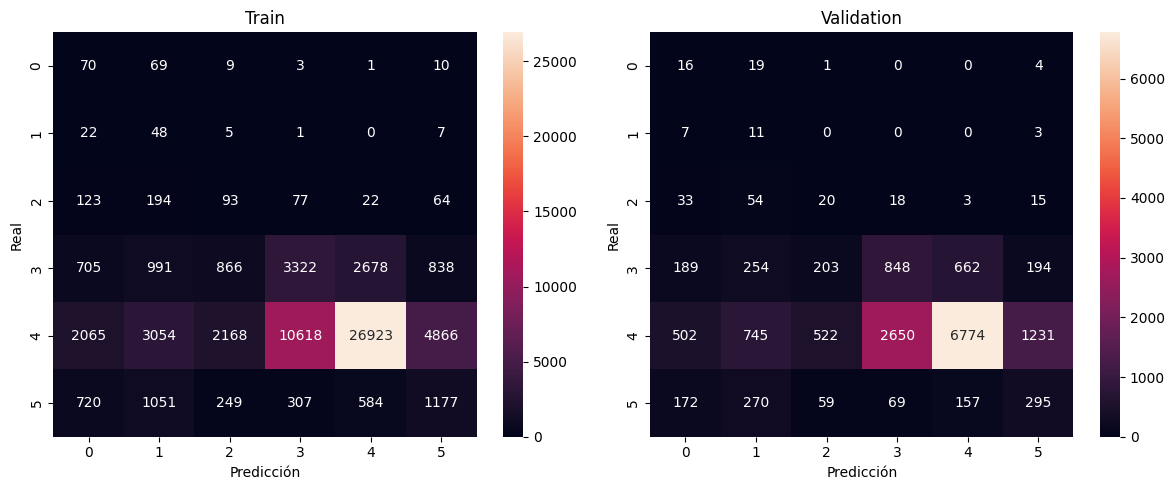

In [29]:
rebalanceo_1 = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rebalanceo_1.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_1 = rebalanceo_1.predict(X_train_scaled)
y_pred_val_rebalanceo_1 = rebalanceo_1.predict(X_val_scaled)

metricas_train = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_1, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_1, y_val_clasificacion)
tabla_metricas_regresion_logistica_1 = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_1)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_1)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_1)
plot_confusion_matrix(cm_train, cm_val)

Ahora intento ponerles pesos personalizados

c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\czava\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


              Train  Validation
Accuracy   0.755641    0.757750
Precision  0.282095    0.243380
Recall     0.228025    0.226987
F1         0.227150    0.222605


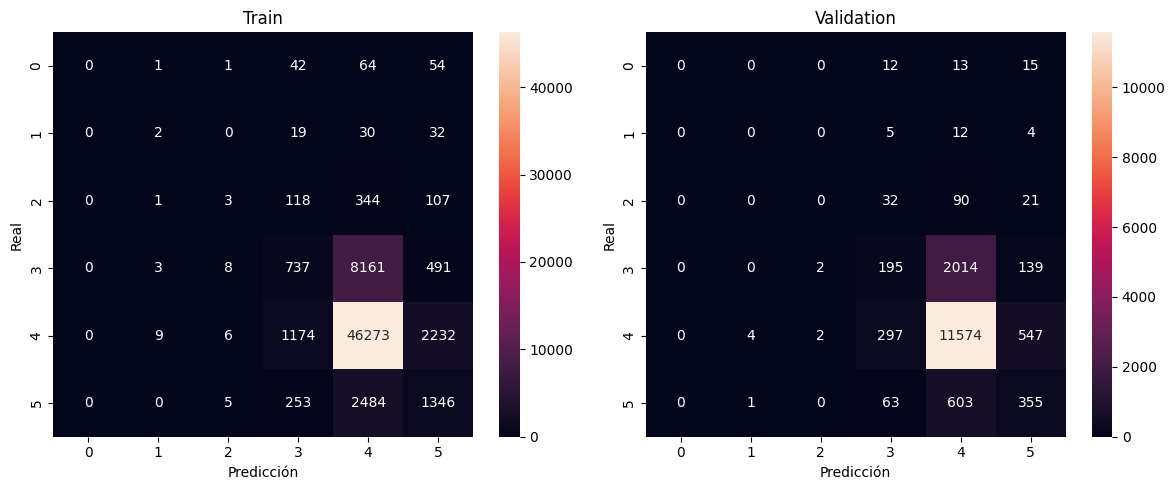

In [45]:
pesos = {1:10, 2:4, 3:2, 4:1, 5:2} #defino diferentes pesos para dar prioridad a las clases mas minoritarias
rebalanceo_2 = LogisticRegression(max_iter = 1000, class_weight = pesos)
rebalanceo_2.fit(X_train_scaled, y_train_clasificacion)

y_pred_train_rebalanceo_2 = rebalanceo_2.predict(X_train_scaled)
y_pred_val_rebalanceo_2 = rebalanceo_2.predict(X_val_scaled)

metricas_train = evaluar_metricas_clasificacion(y_pred_train_rebalanceo_2, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_rebalanceo_2, y_val_clasificacion)
tabla_metricas_regresion_logistica_2 = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_regresion_logistica_2)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_rebalanceo_2)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_rebalanceo_2)
plot_confusion_matrix(cm_train, cm_val)

In [39]:
print("Comparacion de tablas de metricas segun los diferentes rebalanceos")

print("\nModelo sin rebalanceo")
print(tabla_metricas_regresion_logistica_base)

print("\nModelo con rebalanceo predeterminado")
print(tabla_metricas_regresion_logistica_1)

print("\nModelo con rebalanceo con pesos definidos a mano")
print(tabla_metricas_regresion_logistica_2)

Comparacion de tablas de metricas segun los diferentes rebalanceos

Modelo sin rebalanceo
              Train  Validation
Accuracy   0.776500    0.776563
Precision  0.346117    0.310011
Recall     0.167234    0.167152
F1         0.146906    0.146776

Modelo con rebalanceo predeterminado
              Train  Validation
Accuracy   0.494266    0.497750
Precision  0.224562    0.224676
Recall     0.392635    0.376401
F1         0.211261    0.211253

Modelo con rebalanceo con pesos definidos a mano
              Train  Validation
Accuracy   0.763359    0.764500
Precision  0.292556    0.206774
Recall     0.218870    0.214587
F1         0.210723    0.202016
